In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Found 983 images belonging to 6 classes.
Found 250 images belonging to 6 classes.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


31/31 ━━━━━━━━━━━━━━━━━━━━ 424s 11s/step - accuracy: 0.4108 - loss: 1.6111 - val_accuracy: 0.8080 - val_loss: 0.7120
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 14s 366ms/step - accuracy: 0.7579 - loss: 0.7122 - val_accuracy: 0.7920 - val_loss: 0.5762
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 370ms/step - accuracy: 0.7903 - loss: 0.6047 - val_accuracy: 0.7960 - val_loss: 0.4952
Epoch 4/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 389ms/step - accuracy: 0.7929 - loss: 0.5557 - val_accuracy: 0.8080 - val_loss: 0.4724
Epoch 5/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 16s 433ms/step - accuracy: 0.8202 - loss: 0.4950 - val_accuracy: 0.8120 - val_loss: 0.4679
Epoch 6/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 18s 437ms/step - accuracy: 0.8304 - loss: 0.4489 - val_accuracy: 0.8640 - val_loss: 0.4028
Epoch 7/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 17s 431ms/step - accuracy: 0.8414 - loss: 0.4353 - val_accuracy: 0.8760 - val_loss: 0.3550
Epoch 8/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 370ms/step - accuracy: 0.8816 - loss: 0.3268 - val_accuracy:

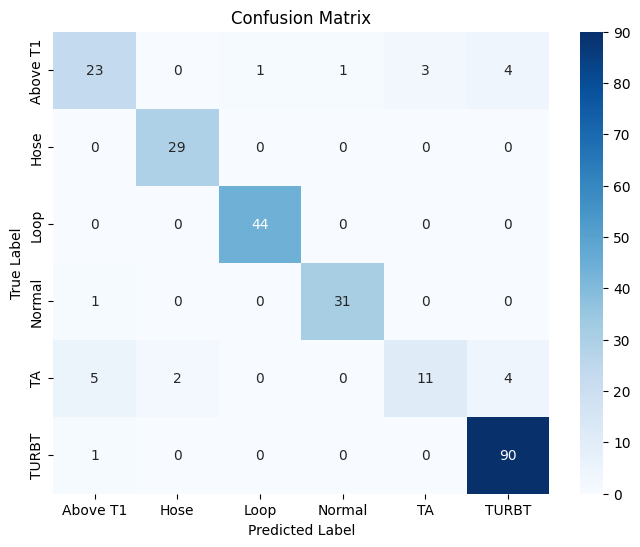

Classification Report
              precision    recall  f1-score   support

    Above T1       0.77      0.72      0.74        32
        Hose       0.94      1.00      0.97        29
        Loop       0.98      1.00      0.99        44
      Normal       0.97      0.97      0.97        32
          TA       0.79      0.50      0.61        22
       TURBT       0.92      0.99      0.95        91

    accuracy                           0.91       250
   macro avg       0.89      0.86      0.87       250
weighted avg       0.91      0.91      0.91       250



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# Importing required libraries
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Define paths to your dataset
train_dir = '/content/drive/MyDrive/BLC Dataset/SAVE_split/train'
test_dir = '/content/drive/MyDrive/BLC Dataset/SAVE_split/test'

# Define the image size and batch size
img_size = (224, 224)  # VGG16 requires 224x224 images
batch_size = 32

# Data augmentation and rescaling for training data
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=20,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

# Only rescaling for test data
test_datagen = ImageDataGenerator(rescale=1./255)

# Load the training and testing datasets
train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size=img_size,
                                                    batch_size=batch_size,
                                                    class_mode='categorical')

test_generator = test_datagen.flow_from_directory(test_dir,
                                                  target_size=img_size,
                                                  batch_size=batch_size,
                                                  class_mode='categorical',
                                                  shuffle=False)

# Load the VGG16 model with ImageNet weights, exclude top layers
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the convolutional base to prevent updating pre-trained weights
for layer in base_model.layers:
    layer.trainable = False

# Adding custom layers for your 6 classes
x = Flatten()(base_model.output)
x = Dense(1024, activation='relu')(x)  # Adding a dense layer
x = Dense(512, activation='relu')(x)
predictions = Dense(6, activation='softmax')(x)  # 6 classes

# Combine base model and custom layers
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model and save the best weights
checkpoint_path = '/content/vgg16_best_weights.keras'  # Changed extension to .keras
checkpoint = tf.keras.callbacks.ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_accuracy', mode='max')

history = model.fit(train_generator,
                    epochs=100,
                    validation_data=test_generator,
                    callbacks=[checkpoint])
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(test_generator)
print(f'Test accuracy: {test_acc:.4f}')

# Predict on test data
Y_pred = model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

# Confusion Matrix and Classification Report
class_labels = list(test_generator.class_indices.keys())

# Confusion matrix
cm = confusion_matrix(test_generator.classes, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Classification report
print('Classification Report')
report = classification_report(test_generator.classes, y_pred, target_names=class_labels)
print(report)

# Download the saved model weights
files.download(checkpoint_path)
